# Method 2: structural survival and UDU similarity

This notebook identifies **potential non-UDU parcels**, not confirmed non-UDUs. A parcel must first remain structurally stable between 2014 and 2017. Stable parcels that resemble known UDUs are then removed using a use-type-specific Mahalanobis-distance model.

Detailed results are retained in `method2_features`. The standardized primary output is `method2_output`, with columns `AIN` and `method2_potential_nonudu` for each eligible 2017 AIN.

In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.covariance import LedoitWolf
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'src').exists() and (candidate / 'data').exists():
            return candidate
    raise RuntimeError('Could not locate the NDSC_HiddenHousing project root')

PROJECT_ROOT = find_project_root(Path.cwd())
CITY_OUTPUT = PROJECT_ROOT / 'data/03_processed/city_of_la'
CITY_TILE_ROOT = PROJECT_ROOT / 'data/02_intermediate/city_of_la/tiles'
MASTER_DB = PROJECT_ROOT / 'data/01_source/all_parcel_data.sqlite'
CURRENT_UDU_REPORT = PROJECT_ROOT / 'data/01_source/UDU Report 02_10_2026.csv'

REFERENCE_YEAR = 2017
CHANGE_EPOCH = (2014, 2017)
ASSESSOR_STABILITY_TOLERANCE_SQFT = 0
UDU_DISTANCE_QUANTILE = 0.90
MIN_KNOWN_UDU_PER_USE_TYPE = 10
ENABLE_CLASSIFIER = False
CLASSIFIER_UDU_QUANTILE = 0.10

## Load the current standardized outputs

Published citywide files are used when available; otherwise the notebook combines completed city tiles. The master database is queried only for AINs present in the pipeline output. Because the master file has 2010, 2016, and 2024 rolls, 2016 is the historical assessor comparison for the 2017 snapshot. The structural gate uses the master's established 2014–2017 sym-difference fields; the newly recomputed change fields are retained with a `pipeline.` prefix for comparison and QA.

In [2]:
def normalize_ain(values):
    return (
        values.astype('string').str.strip().str.replace('-', '', regex=False)
        .str.replace(r'\.0$', '', regex=True).str.zfill(10)
    )

def load_city_table(filename, columns, key):
    published = CITY_OUTPUT / filename
    if published.exists():
        frame = pd.read_parquet(published, columns=columns)
        scope = 'published city output'
    else:
        paths = [
            manifest.parent / filename
            for manifest in sorted(CITY_TILE_ROOT.glob('*/manifest.json'))
        ]
        paths = [path for path in paths if path.exists()]
        if not paths:
            raise RuntimeError(f'No completed output found for {filename}')
        frame = pd.concat(
            [pd.read_parquet(path, columns=columns) for path in paths],
            ignore_index=True,
        )
        scope = f'{len(paths)} completed tiles'
    duplicates = int(frame.duplicated(key).sum())
    frame = frame.drop_duplicates(key).reset_index(drop=True)
    return frame, {'source': scope, 'rows': len(frame), 'duplicates_removed': duplicates}

def load_master_for_ains(ains):
    columns = [
        'AssessorID', 'usecodedescchar2_2016', 'sqftmain_2016',
        'units_2016', 'bedrooms_2016', 'bathrooms_2016',
        'yearbuilt_2016', 'effectiveyearbuilt_2016',
        'totbuildingdatalines_2016', 'roll_landvalue_2016',
        'roll_impvalue_2016', 'area_2014', 'area_2017', 'n_2014', 'n_2017',
        'area_net_1417_2017', 'n_delta_1417_2017',
        'change_type_1417_2017',
    ]
    with sqlite3.connect(MASTER_DB) as connection:
        connection.execute('CREATE TEMP TABLE wanted_ains (AIN TEXT PRIMARY KEY)')
        normalized = pd.Series(ains).dropna().astype(str).unique()
        master_ids = [f'{ain[:4]}-{ain[4:7]}-{ain[7:]}' for ain in normalized]
        connection.executemany(
            'INSERT OR IGNORE INTO wanted_ains VALUES (?)',
            [(ain,) for ain in master_ids],
        )
        query = (
            'SELECT ' + ', '.join(f'p.{column}' for column in columns)
            + ' FROM all_parcel_data p JOIN wanted_ains w ON p.AssessorID = w.AIN'
        )
        master = pd.read_sql_query(query, connection)
    master['AIN'] = normalize_ain(master['AssessorID'])
    if master['AIN'].duplicated().any():
        raise ValueError('Master parcel data must contain one row per normalized AIN')
    return master.drop(columns='AssessorID')

parcel_columns = [
    'AIN', 'site_id', 'parcel.area', 'building.count',
    'building.footprint_area', 'building.floor_area',
    'shape.area.max', 'snapshot.coverage', 'snapshot.far',
    'assessor.ain_count', 'assessor.sqft', 'assessor.units',
    'assessor.bedrooms', 'assessor.bathrooms',
    'assessor.building_records', 'assessor.year_built',
    'assessor.effective_year_built',
]
change_columns = [
    'reference_AIN', 'change_type', 'building_count_delta',
    'area_added_m2', 'area_removed_m2', 'area_changed_fraction',
    'overlap_iou',
]
parcels, parcel_load = load_city_table(
    'parcel_metrics_2017.parquet', parcel_columns, 'AIN'
)
changes, change_load = load_city_table(
    'change_metrics_2014_2017.parquet', change_columns, 'reference_AIN'
)
parcels['AIN'] = normalize_ain(parcels['AIN'])
changes['AIN'] = normalize_ain(changes.pop('reference_AIN'))
changes = changes.rename(columns={
    column: f'pipeline.{column}' for column in changes if column != 'AIN'
})
master = load_master_for_ains(parcels['AIN'])

udu_report = pd.read_csv(
    CURRENT_UDU_REPORT, usecols=['assessor_parcel_number'], encoding='utf-8-sig'
)
udu_report['AIN'] = normalize_ain(udu_report['assessor_parcel_number'])
known_udu_ains = set(udu_report['AIN'].dropna())

display(pd.DataFrame([parcel_load, change_load], index=['2017 parcels', '2014–2017 changes']))

,source,rows,duplicates_removed
2017 parcels,37 completed tiles,666873,19674
2014–2017 changes,37 completed tiles,625360,6177


## Structural-survival screen

Every check is retained as a separate Boolean column. The use-type bounds reproduce the intent of the original notebook. The change test uses the precomputed master classification that supported that method; the current recomputed change table is loaded separately so its 2014 coverage can be audited before it replaces the master classification.

In [3]:
TYPE_CONFIG = {
    'Single Family Residence': {'max_buildings': 1, 'max_lot_sqft': 10_000, 'ratio': (0.5, 2.5)},
    'Double, Duplex, or Two Units': {'max_buildings': 2, 'max_lot_sqft': 12_000, 'ratio': (0.3, 4.0)},
    'Three Units (Any Combination)': {'max_buildings': 3, 'max_lot_sqft': 15_000, 'ratio': (0.3, 4.0)},
    'Four Units  (Any Combination)': {'max_buildings': 4, 'max_lot_sqft': 20_000, 'ratio': (0.3, 4.0)},
    'Five or More Units or Apartments (Any Combination)': {'max_buildings': 8, 'max_lot_sqft': 30_000, 'ratio': (0.2, 6.0)},
    'Store Combination': {'max_buildings': 1, 'max_lot_sqft': 10_000, 'ratio': (0.5, 2.5)},
}

def build_structural_screen(parcels, changes, master):
    data = (
        parcels.merge(changes, on='AIN', how='left', validate='one_to_one')
        .merge(master, on='AIN', how='left', validate='one_to_one')
        .rename(columns={'usecodedescchar2_2016': 'SpecificUseType'})
    )
    data['is_known_udu'] = data['AIN'].isin(known_udu_ains)
    data['floor_area_ratio'] = data['building.floor_area'].div(
        data['assessor.sqft'].where(data['assessor.sqft'].gt(0))
    )
    data['check_eligible_snapshot'] = (
        data['assessor.ain_count'].eq(1)
        & data['assessor.sqft'].gt(0)
        & data['building.floor_area'].gt(0)
        & data['SpecificUseType'].isin(TYPE_CONFIG)
    )
    data['check_no_structural_change'] = (
        data['change_type_1417_2017'].eq('no_change')
        & data['n_delta_1417_2017'].eq(0)
    )
    data['assessor_sqft_delta_2016_2017'] = (
        data['assessor.sqft'] - data['sqftmain_2016']
    )
    data['check_assessor_stable'] = (
        data['sqftmain_2016'].gt(0)
        & data['assessor_sqft_delta_2016_2017'].abs().le(
            ASSESSOR_STABILITY_TOLERANCE_SQFT
        )
    )
    data['check_lot_size'] = False
    data['check_building_count'] = False
    data['check_floor_area_ratio'] = False
    for use_type, config in TYPE_CONFIG.items():
        rows = data['SpecificUseType'].eq(use_type)
        lower, upper = config['ratio']
        data.loc[rows, 'check_lot_size'] = data.loc[rows, 'parcel.area'].le(
            config['max_lot_sqft']
        ).fillna(False).to_numpy(dtype=bool)
        data.loc[rows, 'check_building_count'] = (
            data.loc[rows, 'building.count'].between(1, config['max_buildings'])
            .fillna(False).to_numpy(dtype=bool)
        )
        data.loc[rows, 'check_floor_area_ratio'] = (
            data.loc[rows, 'floor_area_ratio'].between(lower, upper)
            .fillna(False).to_numpy(dtype=bool)
        )
    checks = [
        'check_eligible_snapshot', 'check_no_structural_change',
        'check_assessor_stable', 'check_lot_size',
        'check_building_count', 'check_floor_area_ratio',
    ]
    data['method2_structural_screen'] = data[checks].all(axis=1)
    return data

method2_input = build_structural_screen(parcels, changes, master)
change_source_qa = pd.Series({
    'AINs with master change classification': method2_input['change_type_1417_2017'].notna().sum(),
    'master no_change AINs': method2_input['change_type_1417_2017'].eq('no_change').sum(),
    'AINs with recomputed pipeline classification': method2_input['pipeline.change_type'].notna().sum(),
    'recomputed pipeline no_change AINs': method2_input['pipeline.change_type'].eq('no_change').sum(),
}, name='AINs')
display(change_source_qa.to_frame())
screen_checks = [column for column in method2_input if column.startswith('check_')]
eligible = method2_input.loc[method2_input['check_eligible_snapshot']].copy()
funnel = []
running = pd.Series(True, index=eligible.index)
for check in screen_checks[1:]:
    running &= eligible[check]
    funnel.append({'stage': check.removeprefix('check_'), 'remaining': int(running.sum())})
funnel = pd.DataFrame([{'stage': 'eligible_snapshot', 'remaining': len(eligible)}, *funnel])
display(funnel)
display(
    eligible.groupby('SpecificUseType').agg(
        eligible_ains=('AIN', 'size'),
        known_udu=('is_known_udu', 'sum'),
        structural_survivors=('method2_structural_screen', 'sum'),
    ).sort_values('eligible_ains', ascending=False)
)

,AINs
AINs with master change classification,606924
master no_change AINs,533885
AINs with recomputed pipeline classification,625360
recomputed pipeline no_change AINs,96


,stage,remaining
0,eligible_snapshot,556214
1,no_structural_change,479358
2,assessor_stable,477422
3,lot_size,402113
4,building_count,227565
5,floor_area_ratio,202391


,eligible_ains,known_udu,structural_survivors
SpecificUseType,,,
Single Family Residence,446121,11,117238
"Double, Duplex, or Two Units",43764,92,28982
Five or More Units or Apartments (Any Combination),32724,193,29276
Three Units (Any Combination),14190,76,11881
Four Units (Any Combination),13980,40,12794
Store Combination,5435,16,2220


## Similarity features

The model uses structural and assessor characteristics only. Geography and UDU-report density are intentionally excluded so the model does not simply learn where reporting occurred.

In [4]:
def add_similarity_features(data):
    result = data.copy()
    positive = lambda values: pd.to_numeric(values, errors='coerce').where(lambda x: x > 0)
    result['log_assessor_sqft'] = np.log1p(positive(result['assessor.sqft']))
    result['log_lariac_floor_area'] = np.log1p(positive(result['building.floor_area']))
    result['log_parcel_area'] = np.log1p(positive(result['parcel.area']))
    result['dominance_ratio'] = result['shape.area.max'].div(
        result['building.footprint_area'].where(result['building.footprint_area'].gt(0))
    )
    result['structure_unit_density'] = result['assessor.units'] / result['building.count']
    result['age_2017'] = REFERENCE_YEAR - result['assessor.year_built'].where(
        result['assessor.year_built'].between(1800, REFERENCE_YEAR)
    )
    result['renovation_gap'] = (
        result['assessor.effective_year_built'] - result['assessor.year_built']
    ).where(result['assessor.effective_year_built'].between(1800, REFERENCE_YEAR))
    units = result['assessor.units'].where(result['assessor.units'].gt(0))
    result['bath_per_unit'] = result['assessor.bathrooms'].div(units)
    result['bedrooms_per_1000_sqft'] = (
        1000 * result['assessor.bedrooms'].div(result['assessor.sqft'])
    )
    result['improvement_value_per_sqft'] = result['roll_impvalue_2016'].div(
        result['sqftmain_2016'].where(result['sqftmain_2016'].gt(0))
    )
    total_value = result['roll_landvalue_2016'] + result['roll_impvalue_2016']
    result['land_value_share'] = result['roll_landvalue_2016'].div(
        total_value.where(total_value.gt(0))
    )
    return result

MODEL_FEATURES = [
    'log_assessor_sqft', 'log_lariac_floor_area', 'log_parcel_area',
    'floor_area_ratio', 'building.count', 'snapshot.far',
    'snapshot.coverage', 'dominance_ratio', 'structure_unit_density',
    'age_2017', 'renovation_gap', 'bath_per_unit',
    'bedrooms_per_1000_sqft', 'improvement_value_per_sqft',
    'land_value_share',
]
method2_input = add_similarity_features(method2_input)

## Fit use-type-specific UDU similarity models

The UDU threshold is the selected quantile of leave-one-out known-UDU distances. Each candidate is scored against a model fitted only to known UDUs of the same use type. Median imputation and covariance shrinkage make the calculation more stable with small samples.

In [5]:
def usable_features(training, feature_columns):
    return [
        column for column in feature_columns
        if pd.to_numeric(training[column], errors='coerce').notna().sum() >= 2
        and pd.to_numeric(training[column], errors='coerce').nunique(dropna=True) > 1
    ]

def fit_distance_model(training, scoring, feature_columns):
    columns = usable_features(training, feature_columns)
    if not columns:
        raise ValueError('No usable similarity features')
    train = training[columns].apply(pd.to_numeric, errors='coerce')
    score = scoring[columns].apply(pd.to_numeric, errors='coerce')
    imputer = SimpleImputer(strategy='median')
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(imputer.fit_transform(train))
    score_scaled = scaler.transform(imputer.transform(score))
    covariance = LedoitWolf().fit(train_scaled)
    distances = np.sqrt(covariance.mahalanobis(score_scaled))
    return distances, columns

def leave_one_out_udu_distances(known_udu, feature_columns):
    distances = pd.Series(np.nan, index=known_udu.index, dtype='float64')
    for index in known_udu.index:
        training = known_udu.drop(index=index)
        score = known_udu.loc[[index]]
        distances.loc[index] = fit_distance_model(
            training, score, feature_columns
        )[0][0]
    return distances

def score_mahalanobis_by_use_type(data):
    scored = data.copy()
    scored['method2_mahalanobis_distance'] = np.nan
    scored['method2_udu_distance_percentile'] = np.nan
    scored['method2_distance_threshold'] = np.nan
    diagnostics = []
    for use_type in TYPE_CONFIG:
        known = scored.loc[
            scored['SpecificUseType'].eq(use_type) & scored['is_known_udu']
        ]
        candidates = scored.loc[
            scored['SpecificUseType'].eq(use_type)
            & scored['method2_structural_screen']
            & ~scored['is_known_udu']
        ]
        diagnostic = {
            'SpecificUseType': use_type, 'known_udu': len(known),
            'structural_candidates': len(candidates), 'model_fitted': False,
        }
        if len(known) < MIN_KNOWN_UDU_PER_USE_TYPE or candidates.empty:
            diagnostics.append(diagnostic)
            continue
        oof_distances = leave_one_out_udu_distances(known, MODEL_FEATURES)
        candidate_distances, columns = fit_distance_model(
            known, candidates, MODEL_FEATURES
        )
        threshold = float(oof_distances.quantile(UDU_DISTANCE_QUANTILE))
        scored.loc[known.index, 'method2_mahalanobis_distance'] = oof_distances
        scored.loc[candidates.index, 'method2_mahalanobis_distance'] = candidate_distances
        scored.loc[known.index.union(candidates.index), 'method2_distance_threshold'] = threshold
        reference = np.sort(oof_distances.dropna().to_numpy())
        all_indices = known.index.union(candidates.index)
        all_distances = scored.loc[all_indices, 'method2_mahalanobis_distance']
        scored.loc[all_indices, 'method2_udu_distance_percentile'] = (
            np.searchsorted(reference, all_distances, side='right') / len(reference)
        )
        diagnostic.update({
            'model_fitted': True, 'features_used': len(columns),
            'distance_threshold': threshold,
            'median_udu_distance': float(oof_distances.median()),
        })
        diagnostics.append(diagnostic)
    return scored, pd.DataFrame(diagnostics)

method2_scored, method2_model_diagnostics = score_mahalanobis_by_use_type(
    method2_input
)
display(method2_model_diagnostics)

,SpecificUseType,known_udu,structural_candidates,model_fitted,features_used,distance_threshold,median_udu_distance
0,Single Family Residence,14,117236,True,14,7.817804,3.984263
1,"Double, Duplex, or Two Units",94,28919,True,14,4.982323,3.296037
2,Three Units (Any Combination),78,11811,True,14,4.998041,3.354602
3,Four Units (Any Combination),40,12761,True,14,5.022001,3.190274
4,Five or More Units or Apartments (Any Combinat...,194,29104,True,14,4.650026,3.210034
5,Store Combination,16,2213,True,14,6.319648,3.899152


## Optional classifier

This is disabled by default. When enabled, the classifier distinguishes known UDUs from the structurally stable but unlabeled pool using out-of-fold predictions. Its AUC measures separation from the unlabeled pool, not verified predictive accuracy.

In [6]:
def add_optional_classifier_scores(data):
    result = data.copy()
    result['method2_classifier_score'] = np.nan
    result['method2_classifier_threshold'] = np.nan
    diagnostics = []
    if not ENABLE_CLASSIFIER:
        return result, pd.DataFrame(columns=[
            'SpecificUseType', 'known_udu', 'unlabeled', 'oof_separation_auc',
            'classifier_threshold',
        ])
    for use_type in TYPE_CONFIG:
        rows = result['SpecificUseType'].eq(use_type) & (
            result['is_known_udu'] | result['method2_structural_screen']
        )
        sample = result.loc[rows].copy()
        labels = sample['is_known_udu'].astype(int)
        counts = labels.value_counts()
        if len(counts) < 2 or counts.min() < MIN_KNOWN_UDU_PER_USE_TYPE:
            continue
        folds = min(5, int(counts.min()))
        model = make_pipeline(
            SimpleImputer(strategy='median'), StandardScaler(),
            LogisticRegression(class_weight='balanced', max_iter=2000),
        )
        cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)
        scores = cross_val_predict(
            model, sample[MODEL_FEATURES], labels, cv=cv, method='predict_proba'
        )[:, 1]
        threshold = float(np.quantile(scores[labels.eq(1)], CLASSIFIER_UDU_QUANTILE))
        result.loc[sample.index, 'method2_classifier_score'] = scores
        result.loc[sample.index, 'method2_classifier_threshold'] = threshold
        diagnostics.append({
            'SpecificUseType': use_type, 'known_udu': int(labels.sum()),
            'unlabeled': int(labels.eq(0).sum()),
            'oof_separation_auc': roc_auc_score(labels, scores),
            'classifier_threshold': threshold,
        })
    return result, pd.DataFrame(diagnostics)

method2_scored, method2_classifier_diagnostics = add_optional_classifier_scores(
    method2_scored
)
if ENABLE_CLASSIFIER:
    display(method2_classifier_diagnostics)

## Diagnostics

Candidates to the left of each dashed distance threshold resemble the known-UDU distribution and are excluded. Candidates to the right survive the similarity test.

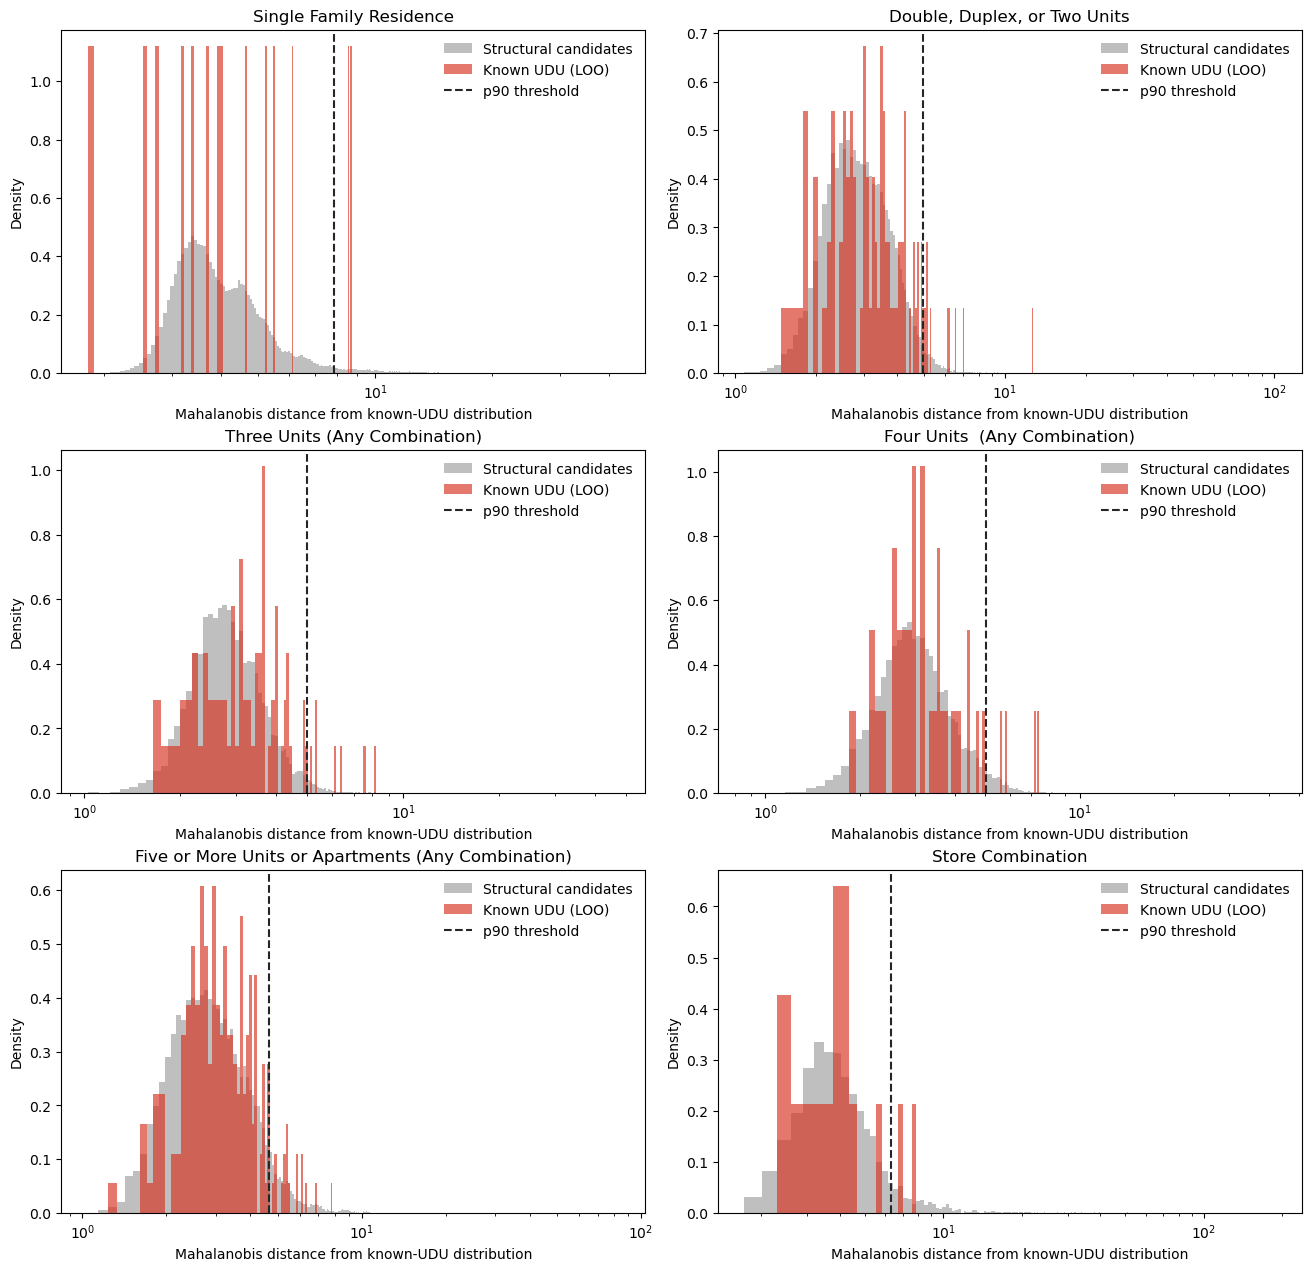

In [7]:
modeled_types = method2_model_diagnostics.loc[
    method2_model_diagnostics['model_fitted'], 'SpecificUseType'
].tolist()
if modeled_types:
    ncols = 2
    nrows = int(np.ceil(len(modeled_types) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4.2 * nrows), constrained_layout=True)
    axes = np.atleast_1d(axes).ravel()
    for ax, use_type in zip(axes, modeled_types):
        group = method2_scored.loc[method2_scored['SpecificUseType'].eq(use_type)]
        known = group.loc[group['is_known_udu'], 'method2_mahalanobis_distance'].dropna()
        candidate = group.loc[
            group['method2_structural_screen'] & ~group['is_known_udu'],
            'method2_mahalanobis_distance',
        ].dropna()
        bins = np.histogram_bin_edges(pd.concat([known, candidate]), bins='auto')
        ax.hist(candidate, bins=bins, density=True, alpha=0.45, color='#737373', label='Structural candidates')
        ax.hist(known, bins=bins, density=True, alpha=0.65, color='#d7301f', label='Known UDU (LOO)')
        threshold = group['method2_distance_threshold'].dropna().iloc[0]
        ax.axvline(threshold, color='#252525', linestyle='--', label=f'p{int(100 * UDU_DISTANCE_QUANTILE)} threshold')
        ax.set_title(use_type, wrap=True)
        ax.set_xlabel('Mahalanobis distance from known-UDU distribution')
        ax.set_ylabel('Density')
        ax.legend(frameon=False)
        ax.set_xscale('log')
    for ax in axes[len(modeled_types):]:
        ax.remove()
    plt.show()
else:
    print('No use type has enough known UDUs and structural candidates to fit a model.')

## Primary output

The original notebook's aggressive rule is preserved when the optional classifier is enabled: a parcel is UDU-like if **either** model identifies it as similar. Without the classifier, the Mahalanobis test alone is used.

In [8]:
def build_method2_features(scored):
    result = scored.loc[scored['check_eligible_snapshot']].copy()
    distance_available = result['method2_mahalanobis_distance'].notna()
    distance_udu_like = (
        distance_available
        & result['method2_mahalanobis_distance'].le(result['method2_distance_threshold'])
    )
    if ENABLE_CLASSIFIER:
        classifier_udu_like = (
            result['method2_classifier_score'].notna()
            & result['method2_classifier_score'].ge(result['method2_classifier_threshold'])
        )
        model_available = distance_available | result['method2_classifier_score'].notna()
        result['method2_udu_like'] = distance_udu_like | classifier_udu_like
    else:
        model_available = distance_available
        result['method2_udu_like'] = distance_udu_like
    result['method2_potential_nonudu'] = (
        result['method2_structural_screen']
        & ~result['is_known_udu']
        & model_available
        & ~result['method2_udu_like']
    )
    result['method2_status'] = 'not_structurally_stable'
    result.loc[result['method2_structural_screen'], 'method2_status'] = 'no_model'
    result.loc[result['method2_structural_screen'] & model_available, 'method2_status'] = 'udu_like'
    result.loc[result['method2_potential_nonudu'], 'method2_status'] = 'potential_nonudu'
    result.loc[result['is_known_udu'], 'method2_status'] = 'known_udu'
    columns = [
        'AIN', 'SpecificUseType', 'is_known_udu',
        'method2_structural_screen', 'method2_mahalanobis_distance',
        'method2_udu_distance_percentile', 'method2_distance_threshold',
        'method2_classifier_score', 'method2_classifier_threshold',
        'method2_udu_like', 'method2_potential_nonudu', 'method2_status',
        *screen_checks,
    ]
    return result[columns].sort_values('AIN').reset_index(drop=True)

method2_features = build_method2_features(method2_scored)
method2_output = method2_features[['AIN', 'method2_potential_nonudu']].copy()
display(method2_features['method2_status'].value_counts().to_frame('AINs'))
display(method2_features.head())
display(method2_output.head())

# Deliberately not saved during method development. When finalized:
# output_path = CITY_OUTPUT / 'method2_potential_nonudu_2017.parquet'
# output_path.parent.mkdir(parents=True, exist_ok=True)
# method2_output.to_parquet(output_path, index=False)

,AINs
method2_status,
not_structurally_stable,353742
udu_like,190797
potential_nonudu,11247
known_udu,428


,AIN,SpecificUseType,is_known_udu,method2_structural_screen,method2_mahalanobis_distance,method2_udu_distance_percentile,method2_distance_threshold,method2_classifier_score,method2_classifier_threshold,method2_udu_like,method2_potential_nonudu,method2_status,check_eligible_snapshot,check_no_structural_change,check_assessor_stable,check_lot_size,check_building_count,check_floor_area_ratio
0,2004001003,Single Family Residence,False,False,NaN,NaN,NaN,NaN,NaN,False,False,not_structurally_stable,True,True,True,True,False,False
1,2004001004,Single Family Residence,False,True,5.157023,0.642857,7.817804,NaN,NaN,True,False,udu_like,True,True,True,True,True,True
2,2004001005,Single Family Residence,False,False,NaN,NaN,NaN,NaN,NaN,False,False,not_structurally_stable,True,True,True,True,True,False
3,2004001008,Single Family Residence,False,False,NaN,NaN,NaN,NaN,NaN,False,False,not_structurally_stable,True,True,True,False,False,False
4,2004001009,Single Family Residence,False,False,NaN,NaN,NaN,NaN,NaN,False,False,not_structurally_stable,True,False,True,False,True,False


,AIN,method2_potential_nonudu
0,2004001003,False
1,2004001004,False
2,2004001005,False
3,2004001008,False
4,2004001009,False


In [ ]:
# AIN-level scores for the cross-method comparison in notebook 04. This is an
# intermediate file, separate from the final output above.
METHOD_SCORES_DIR = PROJECT_ROOT / 'data/02_intermediate/method_scores'
METHOD_SCORES_DIR.mkdir(parents=True, exist_ok=True)
method2_features.to_parquet(METHOD_SCORES_DIR / 'method2_scores_2017.parquet', index=False)
print(f'Saved {len(method2_features):,} AIN rows to {METHOD_SCORES_DIR / "method2_scores_2017.parquet"}')

## Spatial pattern of the Method 2 score

The left map shows the median `method2_udu_distance_percentile` of structurally stable candidates (known UDUs excluded). This is where each candidate's Mahalanobis distance falls within its use type's leave-one-out known-UDU distances, so it can be compared across use types. Values above the dashed-line quantile used in the diagnostics (`UDU_DISTANCE_QUANTILE`) are less UDU-like than almost all known UDUs. The right map shows the share of all eligible AINs flagged `method2_potential_nonudu`, which also reflects where the structural screen removes parcels.

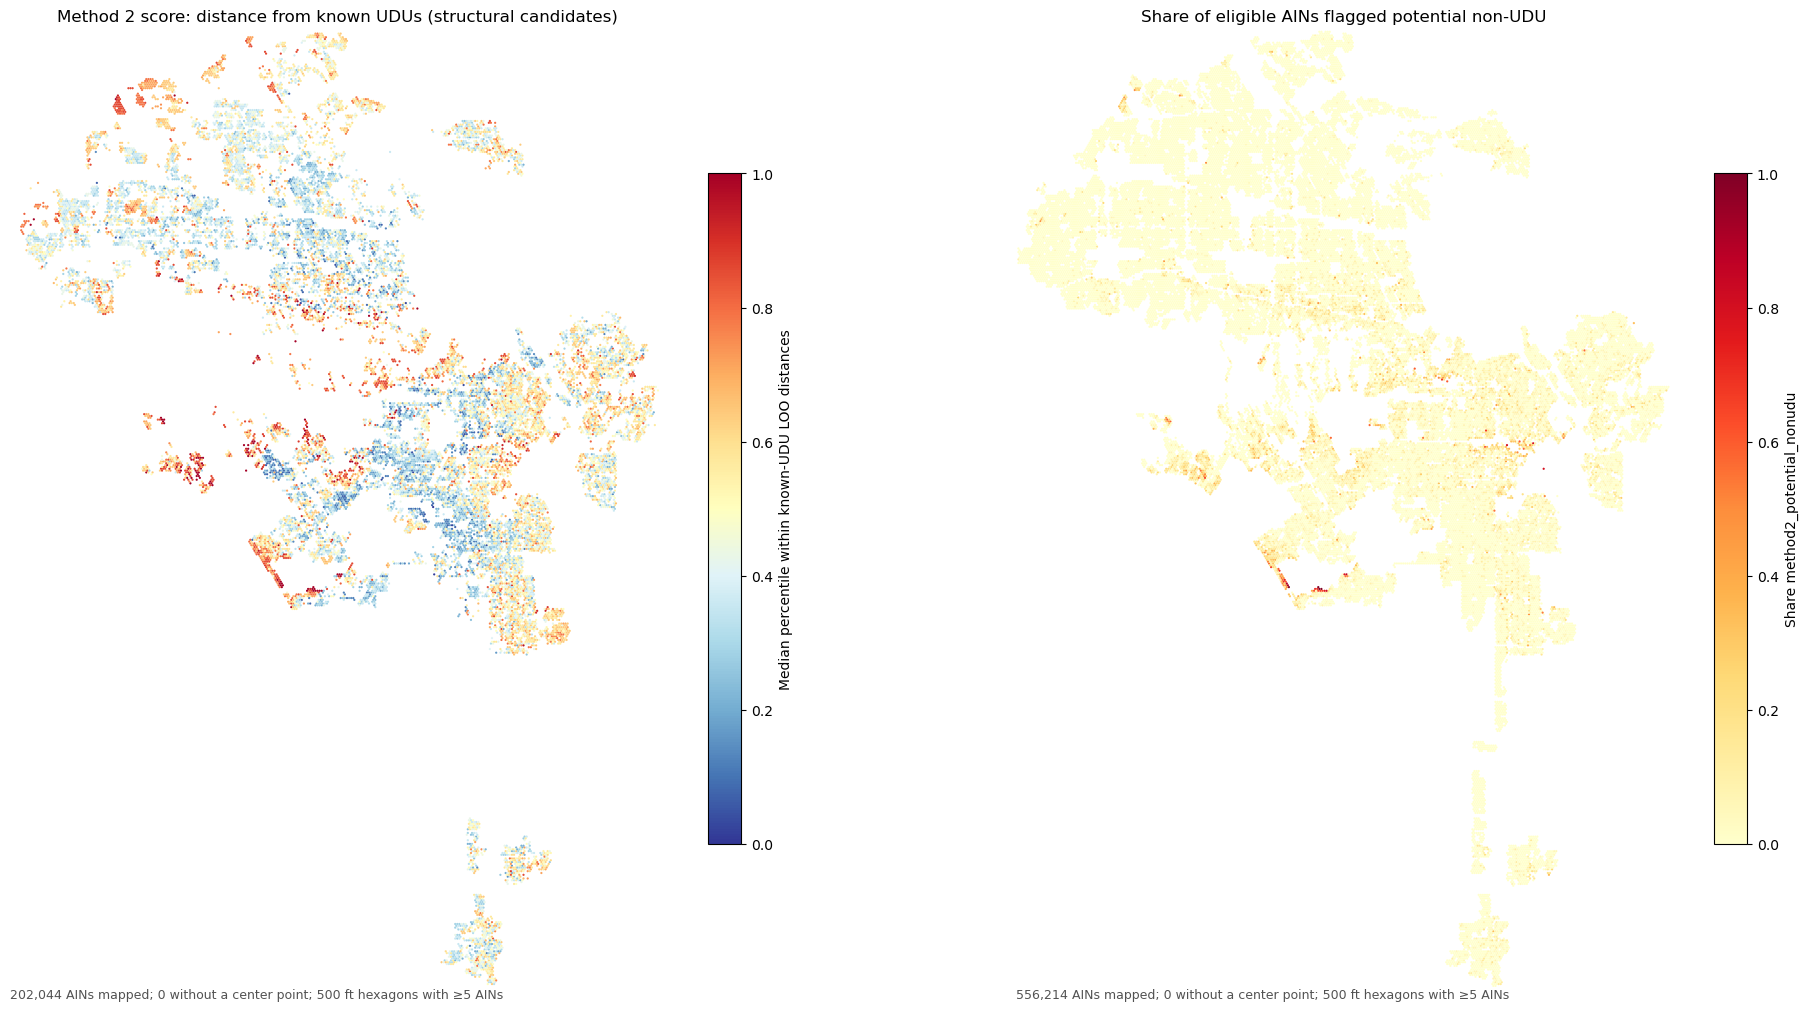

In [17]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.viz import plot_ain_hexbin

candidates = method2_features.loc[
    method2_features['method2_structural_screen'] & ~method2_features['is_known_udu']
]
fig, axes = plt.subplots(1, 2, figsize=(20, 10), constrained_layout=True)
plot_ain_hexbin(
    candidates, 'method2_udu_distance_percentile', ax=axes[0],
    cmap='RdYlBu_r', vmin=0, vmax=1,hex_width_ft = 500,
    title='Method 2 score: distance from known UDUs (structural candidates)',
    colorbar_label='Median percentile within known-UDU LOO distances',
)
plot_ain_hexbin(
    method2_features, 'method2_potential_nonudu', ax=axes[1],
    reduce_function=np.mean, cmap='YlOrRd', vmin=0,hex_width_ft = 500,
    title='Share of eligible AINs flagged potential non-UDU',
    colorbar_label='Share method2_potential_nonudu',
)
plt.show()

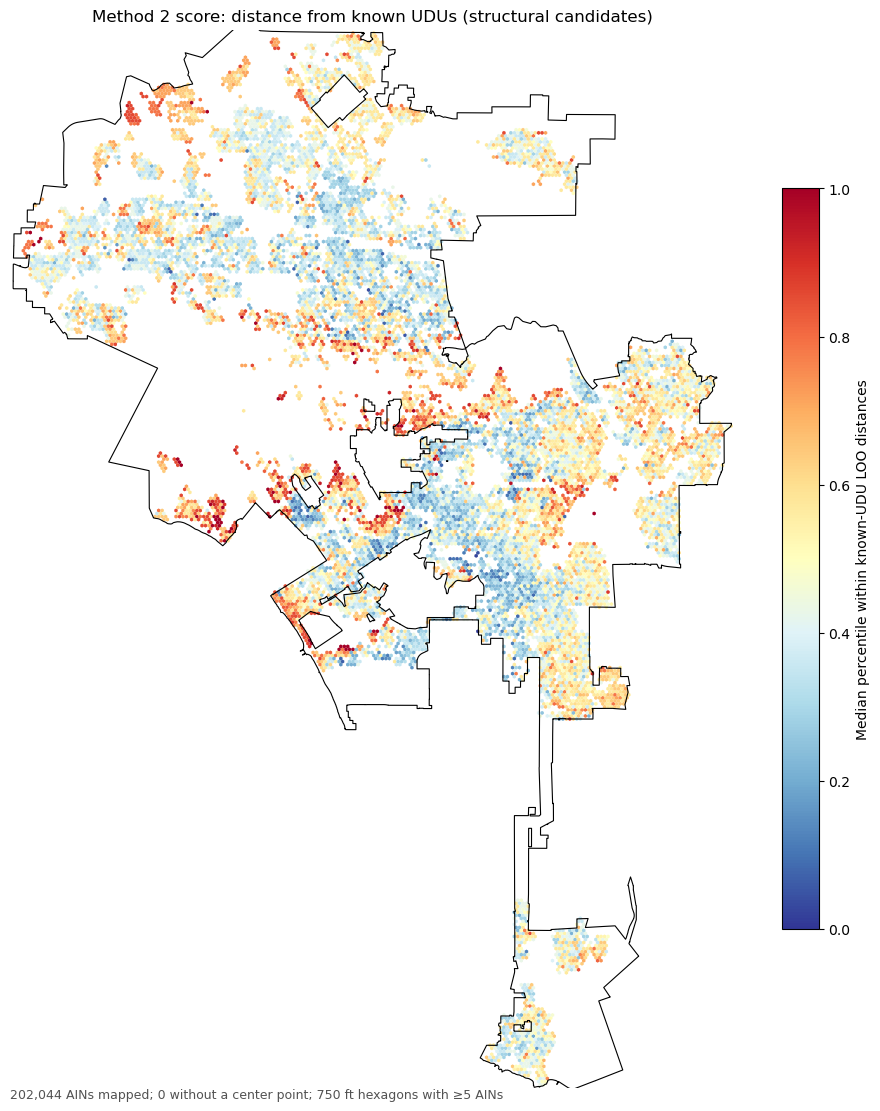

In [28]:
import geopandas as gpd
from src.viz import AIN_POINT_CRS

fig, ax = plt.subplots(figsize=(11, 11), constrained_layout=True)
plot_ain_hexbin(
    candidates, 'method2_udu_distance_percentile', ax=ax,
    cmap='RdYlBu_r', vmin=0, vmax=1, hex_width_ft=750,
    title='Method 2 score: distance from known UDUs (structural candidates)',
    colorbar_label='Median percentile within known-UDU LOO distances',
)
# GeoJSON is WGS84; the hexbins are in EPSG:2229 feet.
lac = gpd.read_file(PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson')
xlim, ylim = ax.get_xlim(), ax.get_ylim()
lac.to_crs(AIN_POINT_CRS).boundary.plot(ax=ax, color='k', linewidth=0.8)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.show()